# EchoNet-Dynamic

## 1. FileList.csv

One row per study. `FileName` is the study id, without `.avi`. The other columns are:

| Column | Meaning |
|---|---|
| `EF` | Ejection fraction, in percent |
| `EDV`, `ESV` | End-diastolic and end-systolic left-ventricle volume, in millilitres |
| `FrameHeight`, `FrameWidth` | Recorded frame size, in pixels |
| `FPS` | Frames per second |
| `NumberOfFrames` | Frames in the AVI |
| `Split` | Official `TRAIN`, `VAL`, or `TEST` split |

The released AVI files are Motion-JPEG and decode as 112×112, three-channel, 8-bit frames. Six studies are listed larger than 112 in this file, and those AVI files still decode as 112×112.

In [68]:
from pathlib import Path
import pandas as pd

In [69]:
DATA = Path("/bigdata/md5_t1fada40cc125fa5312a398ad7cb/dataservers/new_and_reliable/echonet-dynamic")

filelist = pd.read_csv(DATA / "FileList.csv")
filelist.head()

,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL


In [70]:
# add duration in seconds
filelist["DurationSec"] = filelist["NumberOfFrames"] / filelist["FPS"]

In [71]:
filelist.describe()

,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,DurationSec
count,10030.000000,10030.000000,10030.000000,10030.000000,10030.000000,10030.000000,10030.000000,10030.000000
mean,55.748248,43.427433,91.324572,112.392423,112.547159,51.077767,176.533998,3.459169
std,12.371483,35.828098,45.663554,16.040604,22.366033,6.238707,57.879145,1.075927
min,6.907258,4.350710,12.618671,112.000000,112.000000,18.000000,28.000000,0.720000
25%,51.601387,23.686339,62.166669,112.000000,112.000000,50.000000,144.000000,2.848628
50%,59.209109,33.596750,82.084190,112.000000,112.000000,50.000000,171.000000,3.380000
75%,63.958740,49.107316,108.288686,112.000000,112.000000,50.000000,201.000000,3.960000
max,96.967237,612.489815,695.036025,768.000000,1040.000000,138.000000,1002.000000,20.040000


In [72]:
print(
    f"average frames {filelist.NumberOfFrames.mean():.1f}   "
    f"median {filelist.NumberOfFrames.median():.0f}   "
    f"min {filelist.NumberOfFrames.min():.0f}   "
    f"max {filelist.NumberOfFrames.max():.0f}"
)
print(
    f"average fps {filelist.FPS.mean():.1f}   median {filelist.FPS.median():.0f}   "
    f"most common {int(filelist.FPS.mode().iloc[0])} "
    f"({(filelist.FPS == filelist.FPS.mode().iloc[0]).mean() * 100:.1f}% of studies)"
)
print(
    f"average duration {filelist.DurationSec.mean():.2f} s   "
    f"median {filelist.DurationSec.median():.2f} s"
)
print("recorded frame size")
print(filelist.groupby(["FrameHeight", "FrameWidth"]).size().rename("studies"))
print("official split")
print(filelist["Split"].value_counts())


average frames 176.5   median 171   min 28   max 1002
average fps 51.1   median 50   most common 50 (79.4% of studies)
average duration 3.46 s   median 3.38 s
recorded frame size
FrameHeight  FrameWidth
112          112           10024
768          1024              5
             1040              1
Name: studies, dtype: int64
official split
Split
TRAIN    7465
VAL      1288
TEST     1277
Name: count, dtype: int64


Histograms of the numeric columns, and the official split.

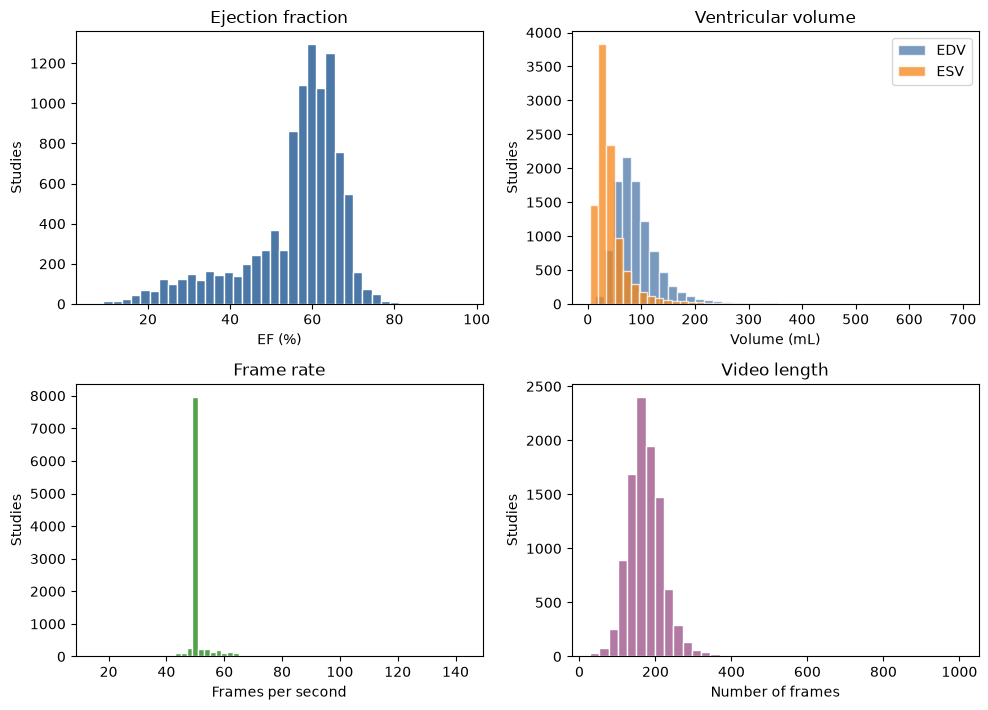

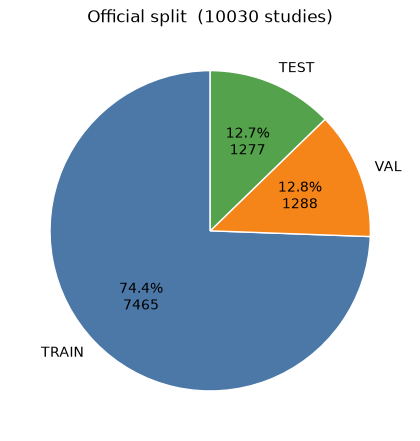

In [73]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 7.2))

axes[0, 0].hist(filelist["EF"], bins=40, color="#4c78a8", edgecolor="white")
axes[0, 0].set_title("Ejection fraction")
axes[0, 0].set_xlabel("EF (%)")
axes[0, 0].set_ylabel("Studies")

axes[0, 1].hist(filelist["EDV"], bins=40, color="#4c78a8", alpha=0.75, label="EDV", edgecolor="white")
axes[0, 1].hist(filelist["ESV"], bins=40, color="#f58518", alpha=0.75, label="ESV", edgecolor="white")
axes[0, 1].set_title("Ventricular volume")
axes[0, 1].set_xlabel("Volume (mL)")
axes[0, 1].set_ylabel("Studies")
axes[0, 1].legend()

axes[1, 0].hist(filelist["FPS"], bins=range(15, 145, 2), color="#54a24b", edgecolor="white")
axes[1, 0].set_title("Frame rate")
axes[1, 0].set_xlabel("Frames per second")
axes[1, 0].set_ylabel("Studies")

axes[1, 1].hist(filelist["NumberOfFrames"], bins=40, color="#b279a2", edgecolor="white")
axes[1, 1].set_title("Video length")
axes[1, 1].set_xlabel("Number of frames")
axes[1, 1].set_ylabel("Studies")

fig.tight_layout()
plt.show()

counts = filelist["Split"].value_counts().reindex(["TRAIN", "VAL", "TEST"])
total = int(counts.sum())

def split_label(pct):
    count = int(round(pct / 100 * total))
    return f"{pct:.1f}%\n{count}"

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.pie(
    counts,
    labels=counts.index,
    colors=["#4c78a8", "#f58518", "#54a24b"],
    autopct=split_label,
    startangle=90,
    wedgeprops={"edgecolor": "white"},
)
ax.set_title(f"Official split  ({total} studies)")
plt.show()


## 2. VolumeTracings.csv

One row is one Simpson chord of the left-ventricle cavity. `FileName` includes the `.avi` suffix, unlike `FileList.csv`. `Frame` is the video frame index. `(X1, Y1)` and `(X2, Y2)` are the two ends of the chord, in pixels.

Each traced frame starts with the long-axis chord. The remaining chords are the cavity diameters. Every study in this file has two traced frames. The larger outline is end-diastole and the smaller outline is end-systole.

In [91]:
tracings = pd.read_csv(DATA / "VolumeTracings.csv")
tracings["Study"] = tracings["FileName"].str.replace(".avi", "", regex=False)

tracings.head()

,FileName,X1,Y1,X2,Y2,Frame,Study
0,0X100009310A3BD7FC.avi,51.260417,15.348958,64.932292,69.125000,46,0X100009310A3BD7FC
1,0X100009310A3BD7FC.avi,50.037611,17.167841,53.367222,16.321330,46,0X100009310A3BD7FC
2,0X100009310A3BD7FC.avi,49.157378,20.407629,57.090549,18.390722,46,0X100009310A3BD7FC
3,0X100009310A3BD7FC.avi,48.538173,23.581055,59.997339,20.667707,46,0X100009310A3BD7FC
4,0X100009310A3BD7FC.avi,47.918968,26.754480,62.904129,22.944693,46,0X100009310A3BD7FC


In [93]:
from IPython.display import display

n_studies = tracings.Study.nunique()
missing = sorted(set(filelist.FileName) - set(tracings.Study))
coverage = pd.DataFrame(
    {"studies": [len(filelist), n_studies, len(missing)]},
    index=["in FileList", "with tracings", "with no tracings"],
)
display(coverage)
print("studies with no tracing rows:", ", ".join(missing))


,studies
in FileList,10030
with tracings,10025
with no tracings,6


studies with no tracing rows: 0X234005774F4CB5CD, 0X2DC68261CBCC04AE, 0X35291BE9AB90FB89, 0X5515B0BD077BE68A, 0X5DD5283AC43CCDD1, 0X6C435C1B417FDE8A


In [94]:
frames_per_study = tracings.groupby("Study").Frame.nunique()
frames_per_study.value_counts().sort_index().rename_axis("traced frames").to_frame("studies")

,studies
traced frames,
2,10025


In [ ]:
chords = tracings.groupby(["Study", "Frame"]).size()
display(chords.describe()[["min", "25%", "50%", "mean", "75%", "max"]].to_frame("chords"))
print(f"{(chords == 21).mean() * 100:.1f}% of traced frames have 21 chords")

## 3. EDV and ESV tracings

Set `filename` to a study id from `FileList.csv` (with or without `.avi`). The cells below load that video, read its `FileList.csv` row, and draw the two contours from `VolumeTracings.csv`.

The larger contour is end-diastole and is the frame for `EDV`. The smaller contour is end-systole and is the frame for `ESV`.

### 3.1. Load metadata

In [ ]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

filename = "0X100009310A3BD7FC"


In [77]:
match = filelist.loc[filelist["FileName"] == filename]
if match.empty:
    raise KeyError(f"{stem} is not in FileList.csv")
info = match.iloc[0]
info

FileName          0X100009310A3BD7FC
EF                         78.498406
ESV                        14.881368
EDV                        69.210534
FrameHeight                      112
FrameWidth                       112
FPS                               50
NumberOfFrames                   174
Split                            VAL
DurationSec                     3.48
Name: 0, dtype: object

In [78]:
tracings = tracings.loc[tracings["FileName"] == f"{stem}.avi"].copy()
if tracings.empty:
    raise KeyError(f"{stem} has no rows in VolumeTracings.csv")
tracings.head()

,FileName,X1,Y1,X2,Y2,Frame,Study
0,0X100009310A3BD7FC.avi,51.260417,15.348958,64.932292,69.125000,46,0X100009310A3BD7FC
1,0X100009310A3BD7FC.avi,50.037611,17.167841,53.367222,16.321330,46,0X100009310A3BD7FC
2,0X100009310A3BD7FC.avi,49.157378,20.407629,57.090549,18.390722,46,0X100009310A3BD7FC
3,0X100009310A3BD7FC.avi,48.538173,23.581055,59.997339,20.667707,46,0X100009310A3BD7FC
4,0X100009310A3BD7FC.avi,47.918968,26.754480,62.904129,22.944693,46,0X100009310A3BD7FC


In [79]:
len(tracings)

42

### 3.2. Understand the data

In [80]:
# `read_frame` opens the video and returns one frame as an RGB image.
def read_frame(path: Path, frame_index: int) -> np.ndarray:
    # Opens the video file
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        capture.release()
        raise FileNotFoundError(path)

    # Gets the number of frames in the video
    n_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))

    # Checks if the frame index is out of bounds
    if frame_index < 0 or frame_index > n_frames - 1:
        capture.release()
        raise IndexError(
            f"Frame {frame_index} is outside 0..{n_frames - 1} for {path.name}"
        )

    # cv2.CAP_PROP_POS_FRAMES is the property that stores the current frame index
    # here we set the current frame index to the frame index we want to read
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame_index)

    # Reads the frame
    ok, frame = capture.read()
    capture.release()

    # Checks if the frame was read successfully
    if not ok or frame is None:
        raise RuntimeError(f"Could not read frame {frame_index} from {path.name}")
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

In [81]:
long_axis = tracings.iloc[0]
print(long_axis)

frame = read_frame(video_path, int(long_axis.Frame))

FileName    0X100009310A3BD7FC.avi
X1                       51.260417
Y1                       15.348958
X2                       64.932292
Y2                          69.125
Frame                           46
Study           0X100009310A3BD7FC
Name: 0, dtype: object


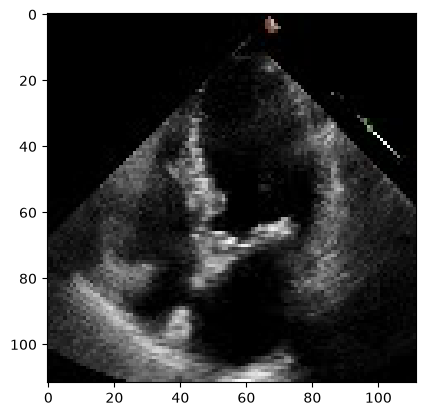

In [82]:
plt.imshow(frame)
plt.show()

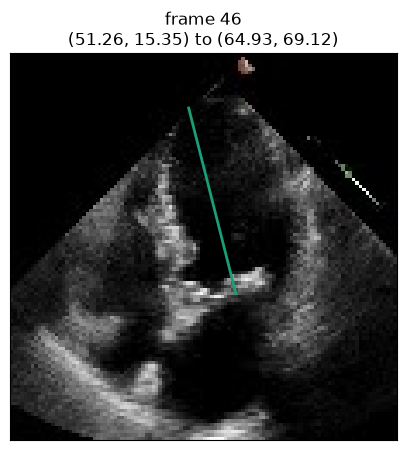

In [83]:
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.imshow(frame)
ax.plot(
    [long_axis.X1, long_axis.X2],
    [long_axis.Y1, long_axis.Y2],
    color="#1b9e77",
    lw=2,
)
ax.set_title(
    f"frame {int(long_axis.Frame)}\n"
    f"({long_axis.X1:.2f}, {long_axis.Y1:.2f}) to ({long_axis.X2:.2f}, {long_axis.Y2:.2f})"
)
ax.set_xticks([])
ax.set_yticks([])
fig.tight_layout()
plt.show()

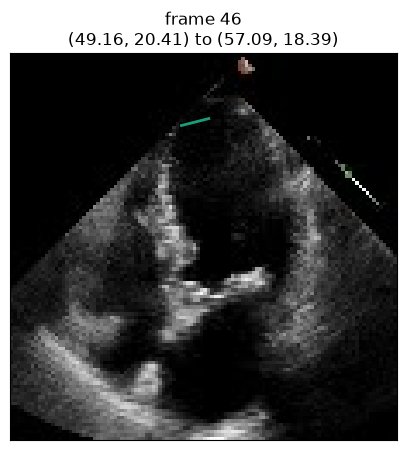

In [84]:
random_line = tracings.iloc[2]

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.imshow(frame)
ax.plot(
    [random_line.X1, random_line.X2],
    [random_line.Y1, random_line.Y2],
    color="#1b9e77",
    lw=2,
)
ax.set_title(
    f"frame {int(random_line.Frame)}\n"
    f"({random_line.X1:.2f}, {random_line.Y1:.2f}) to ({random_line.X2:.2f}, {random_line.Y2:.2f})"
)
ax.set_xticks([])
ax.set_yticks([])
fig.tight_layout()
plt.show()

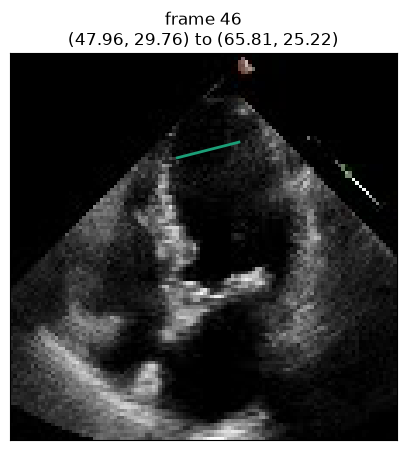

In [85]:
random_line = tracings.iloc[5]

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.imshow(frame)
ax.plot(
    [random_line.X1, random_line.X2],
    [random_line.Y1, random_line.Y2],
    color="#1b9e77",
    lw=2,
)
ax.set_title(
    f"frame {int(random_line.Frame)}\n"
    f"({random_line.X1:.2f}, {random_line.Y1:.2f}) to ({random_line.X2:.2f}, {random_line.Y2:.2f})"
)
ax.set_xticks([])
ax.set_yticks([])
fig.tight_layout()
plt.show()

In [86]:
# `polygon_area` measures the cavity outline, skipping the long-axis chord, so the larger frame can be labeled EDV.

def polygon_area(contour: pd.DataFrame) -> float:
    walls = contour.iloc[1:]
    x = np.concatenate([walls["X1"].to_numpy(), walls["X2"].to_numpy()[::-1]])
    y = np.concatenate([walls["Y1"].to_numpy(), walls["Y2"].to_numpy()[::-1]])
    return float(0.5 * np.abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1))))

In [87]:
phases = []
for frame_index, contour in tracings.groupby("Frame", sort=False):
    print(frame_index, len(contour))
    print(contour.head())
    phases.append({"frame": int(frame_index), "contour": contour, "area": polygon_area(contour)})
    
phases = sorted(phases, key=lambda item: item["area"], reverse=True)
ed, es = phases[0], phases[1]

print(f"{stem}: larger contour is EDV (frame {ed['frame']}), smaller contour is ESV (frame {es['frame']})")
display(info.to_frame("FileList").T)


46 21
                 FileName         X1         Y1         X2         Y2  Frame  \
0  0X100009310A3BD7FC.avi  51.260417  15.348958  64.932292  69.125000     46   
1  0X100009310A3BD7FC.avi  50.037611  17.167841  53.367222  16.321330     46   
2  0X100009310A3BD7FC.avi  49.157378  20.407629  57.090549  18.390722     46   
3  0X100009310A3BD7FC.avi  48.538173  23.581055  59.997339  20.667707     46   
4  0X100009310A3BD7FC.avi  47.918968  26.754480  62.904129  22.944693     46   

                Study  
0  0X100009310A3BD7FC  
1  0X100009310A3BD7FC  
2  0X100009310A3BD7FC  
3  0X100009310A3BD7FC  
4  0X100009310A3BD7FC  
61 21
                  FileName         X1         Y1         X2         Y2  Frame  \
21  0X100009310A3BD7FC.avi  56.000000  19.541667  61.651042  62.744792     61   
22  0X100009310A3BD7FC.avi  55.615298  20.695774  57.093303  20.502448     61   
23  0X100009310A3BD7FC.avi  54.991780  22.984906  59.279910  22.424012     61   
24  0X100009310A3BD7FC.avi  54.486521  

,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split,DurationSec
FileList,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL,3.48


`draw_tracing` plots every Simpson chord and the closed cavity outline on the frame.

In [88]:
def draw_tracing(ax, contour: pd.DataFrame, color: str) -> None:
    for x1, y1, x2, y2 in contour[["X1", "Y1", "X2", "Y2"]].to_numpy():
        ax.plot([x1, x2], [y1, y2], color=color, lw=0.8, alpha=0.9)
    walls = contour.iloc[1:]
    x = np.concatenate([walls["X1"].to_numpy(), walls["X2"].to_numpy()[::-1], walls["X1"].to_numpy()[:1]])
    y = np.concatenate([walls["Y1"].to_numpy(), walls["Y2"].to_numpy()[::-1], walls["Y1"].to_numpy()[:1]])
    ax.plot(x, y, color=color, lw=1.6)

Load the `FileList` row for this filename, then call the larger contour EDV and the smaller one ESV.

Show the EDV frame and the ESV frame with their tracings, and the `FileList` values in the title.

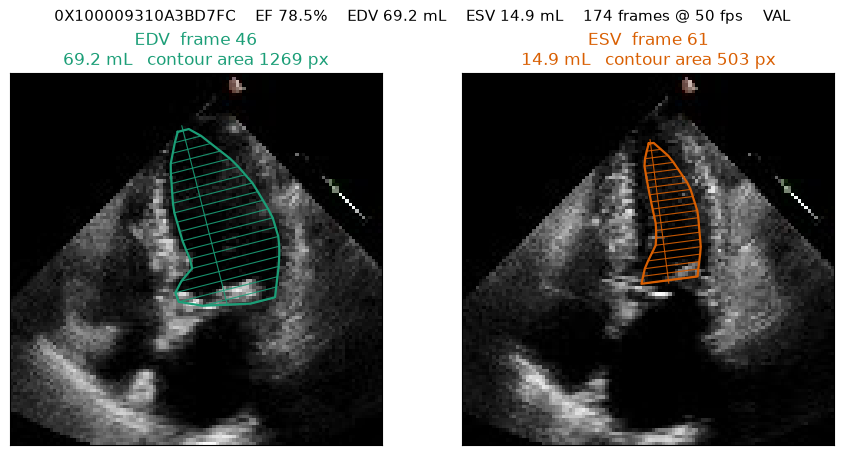

In [89]:
panels = [
    ("EDV", ed, "#1b9e77", float(info.EDV)),
    ("ESV", es, "#d95f02", float(info.ESV)),
]

fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.6))
for ax, (name, phase, color, volume) in zip(axes, panels):
    frame = read_frame(video_path, phase["frame"])
    ax.imshow(frame)
    draw_tracing(ax, phase["contour"], color)
    ax.set_title(
        f"{name}  frame {phase['frame']}\n"
        f"{volume:.1f} mL   contour area {phase['area']:.0f} px",
        color=color,
    )
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(
    f"{stem}    EF {info.EF:.1f}%    EDV {info.EDV:.1f} mL    ESV {info.ESV:.1f} mL"
    f"    {info.NumberOfFrames:.0f} frames @ {info.FPS:.0f} fps    {info.Split}",
    fontsize=11,
)
fig.tight_layout()
plt.show()